In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Dropout,
    GlobalAveragePooling2D,
    Dense,
    Rescaling,
    RandomRotation,
    RandomZoom,
    RandomTranslation
)

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")

TensorFlow version: 2.22.0-rc0
All libraries imported successfully!


In [2]:
base_dir = "C:/Users/nanda/Pneumonia_Detection/Dataset/chest_xray"

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")
val_dir = os.path.join(base_dir, "val")

print("Training folder exists:", os.path.exists(train_dir))
print("Testing folder exists:", os.path.exists(test_dir))
print("Validation folder exists:", os.path.exists(val_dir))

Training folder exists: True
Testing folder exists: True
Validation folder exists: True


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    validation_split=0.2,
    subset="validation",
    seed=42
)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.


In [4]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

Found 624 files belonging to 2 classes.


In [5]:
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Training batches: 131
Validation batches: 33
Testing batches: 20


In [6]:
data_augmentation = tf.keras.Sequential([
    RandomRotation(0.05),
    RandomZoom(0.1),
    RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

print("Data augmentation created successfully!")

Data augmentation created successfully!


In [7]:
normalization_layer = Rescaling(1./255)

print("Normalization layer created successfully!")

Normalization layer created successfully!


In [8]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [9]:
model2 = Sequential([

    Input(shape=(224, 224, 3)),

    # Data augmentation and normalization
    data_augmentation,
    normalization_layer,

    # First convolution block
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Second convolution block
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Third convolution block
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Reduce overfitting
    Dropout(0.4),

    # Classification layers
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

In [10]:
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
model2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

print("Model 2 compiled successfully!")

Model 2 compiled successfully!


In [12]:
# Add training callbacks
# We'll use:
# 1. EarlyStopping – stops training when validation performance stops improving.
# 2. ReduceLROnPlateau – reduces the learning rate when validation loss stops improving.
# 3. ModelCheckpoint – saves the best-performing model automatically.
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)
os.makedirs("../models", exist_ok=True)
checkpoint = ModelCheckpoint(
    "../models/model2_best.keras",
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [13]:
y_train = np.concatenate([
    labels.numpy().ravel()
    for images, labels in train_ds
])

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Model 2 class weights:", class_weights)

Model 2 class weights: {np.float32(0.0): np.float64(1.9107142857142858), np.float32(1.0): np.float64(0.6772151898734177)}


In [14]:
history2 = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]
)

Epoch 1/30


C:\Users\nanda\.conda\envs\notebook-env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.7853 - auc: 0.8919 - loss: 0.4321 - precision: 0.9479 - recall: 0.7504
Epoch 1: val_loss improved from None to 0.55185, saving model to ../models/model2_best.keras

Epoch 1: finished saving model to ../models/model2_best.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 936s 7s/step - accuracy: 0.7853 - auc: 0.8919 - loss: 0.4321 - precision: 0.9479 - recall: 0.7504 - val_accuracy: 0.7613 - val_auc: 0.7194 - val_loss: 0.5518 - val_precision: 0.7613 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8634 - auc: 0.9349 - loss: 0.3185 - precision: 0.9686 - recall: 0.8423
Epoch 2: val_loss did not improve from 0.55185
131/131 ━━━━━━━━━━━━━━━━━━━━ 916s 7s/step - accuracy: 0.8634 - auc: 0.9349 - loss: 0.3185 - precision: 0.9686 - recall: 0.8423 - val_accuracy: 0.7613 - val_auc: 0.8503 - val_loss: 0.5529 - val_precision: 0.7613 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/30
131/1

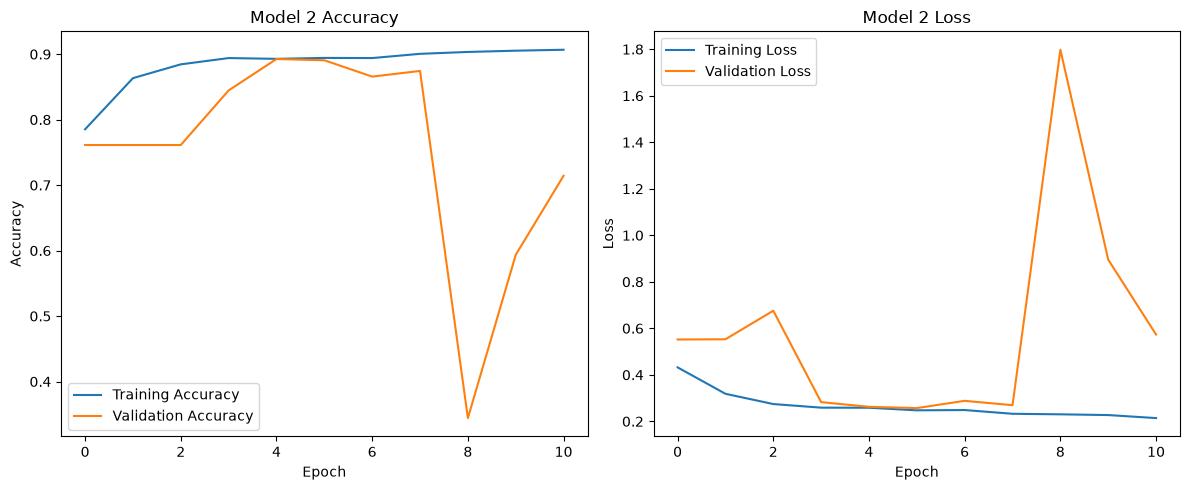

In [16]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(history2.history['accuracy'], label='Training Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model 2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')

plt.title('Model 2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
test_results2 = model2.evaluate(test_ds)

print("Model 2 Test Loss:", test_results2[0])
print("Model 2 Test Accuracy:", test_results2[1])
print("Model 2 Test Precision:", test_results2[2])
print("Model 2 Test Recall:", test_results2[3])
print("Model 2 Test AUC:", test_results2[4])

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 400ms/step - accuracy: 0.8093 - auc: 0.8805 - loss: 0.4900 - precision: 0.8219 - recall: 0.8872
Model 2 Test Loss: 0.4899856448173523
Model 2 Test Accuracy: 0.8092948794364929
Model 2 Test Precision: 0.8218527436256409
Model 2 Test Recall: 0.8871794939041138
Model 2 Test AUC: 0.8805446028709412


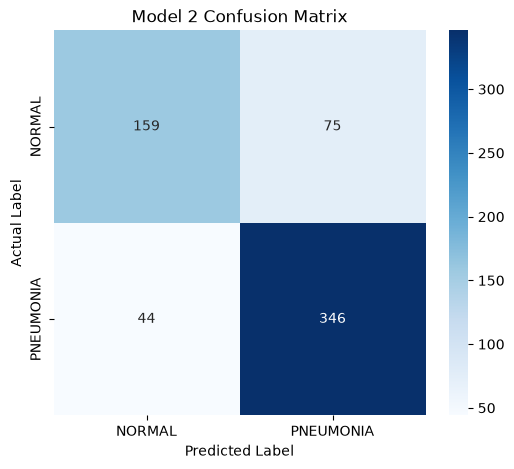

              precision    recall  f1-score   support

      NORMAL       0.78      0.68      0.73       234
   PNEUMONIA       0.82      0.89      0.85       390

    accuracy                           0.81       624
   macro avg       0.80      0.78      0.79       624
weighted avg       0.81      0.81      0.81       624



In [18]:
y_test_true2 = []
y_test_prob2 = []

for images, labels in test_ds:
    predictions = model2(images, training=False)

    y_test_true2.extend(labels.numpy().ravel())
    y_test_prob2.extend(predictions.numpy().ravel())

y_test_true2 = np.array(y_test_true2)
y_test_prob2 = np.array(y_test_prob2)

y_test_pred2 = (y_test_prob2 >= 0.5).astype(int)

cm2 = confusion_matrix(y_test_true2, y_test_pred2)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm2,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['NORMAL', 'PNEUMONIA'],
    yticklabels=['NORMAL', 'PNEUMONIA']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Model 2 Confusion Matrix')
plt.show()

print(classification_report(
    y_test_true2,
    y_test_pred2,
    target_names=['NORMAL', 'PNEUMONIA']
))

In [19]:
model2.save("../models/model2_final.keras")

print("Model 2 saved successfully!")

Model 2 saved successfully!


In [20]:
#threshold tuning
from sklearn.metrics import classification_report, confusion_matrix

# Collect validation labels and predictions
y_val_true2 = []
y_val_prob2 = []

for images, labels in val_ds:
    predictions = model2(images, training=False)

    y_val_true2.extend(labels.numpy().ravel())
    y_val_prob2.extend(predictions.numpy().ravel())

y_val_true2 = np.array(y_val_true2)
y_val_prob2 = np.array(y_val_prob2)

# Compare thresholds
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:

    y_val_pred2 = (y_val_prob2 >= threshold).astype(int)

    print("\nThreshold:", threshold)

    print(confusion_matrix(y_val_true2, y_val_pred2))

    print(classification_report(
        y_val_true2,
        y_val_pred2,
        target_names=['NORMAL', 'PNEUMONIA'],
        zero_division=0
    ))


Threshold: 0.3
[[236  13]
 [ 73 721]]
              precision    recall  f1-score   support

      NORMAL       0.76      0.95      0.85       249
   PNEUMONIA       0.98      0.91      0.94       794

    accuracy                           0.92      1043
   macro avg       0.87      0.93      0.89      1043
weighted avg       0.93      0.92      0.92      1043


Threshold: 0.4
[[238  11]
 [ 88 706]]
              precision    recall  f1-score   support

      NORMAL       0.73      0.96      0.83       249
   PNEUMONIA       0.98      0.89      0.93       794

    accuracy                           0.91      1043
   macro avg       0.86      0.92      0.88      1043
weighted avg       0.92      0.91      0.91      1043


Threshold: 0.5
[[240   9]
 [105 689]]
              precision    recall  f1-score   support

      NORMAL       0.70      0.96      0.81       249
   PNEUMONIA       0.99      0.87      0.92       794

    accuracy                           0.89      1043
   macro av

      Metric  Model 1  Model 2
0   Accuracy    73.56    80.93
1  Precision    72.55    82.19
2     Recall    92.82    88.72
3        AUC    83.41    88.05


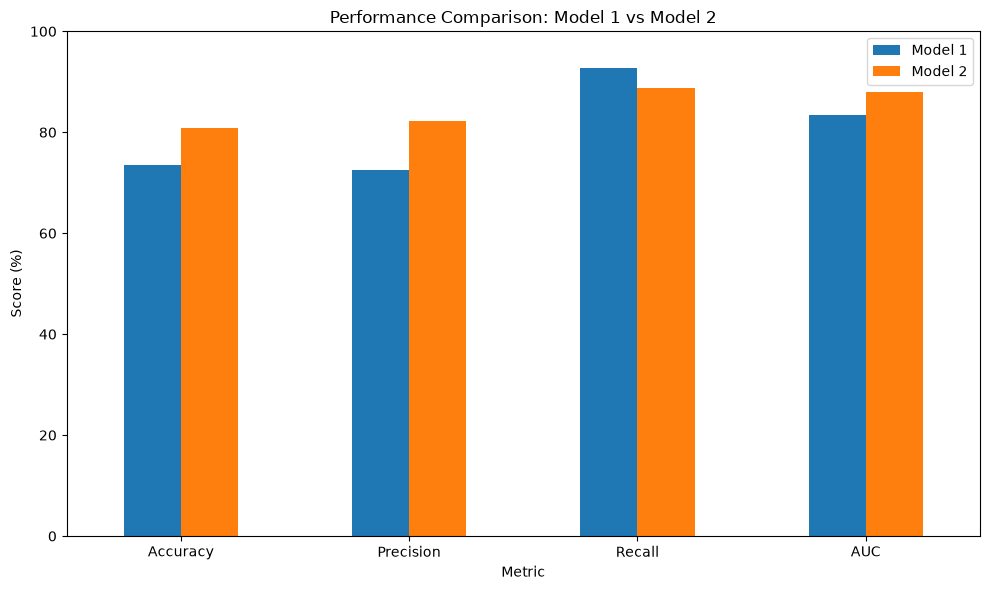

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "AUC"],
    "Model 1": [73.56, 72.55, 92.82, 83.41],
    "Model 2": [80.93, 82.19, 88.72, 88.05]
})

print(comparison)

comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison: Model 1 vs Model 2")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
from tensorflow.keras.utils import load_img, img_to_array

def predict_pneumonia(image_path):

    # Load and resize image
    img = load_img(
        image_path,
        target_size=(224, 224)
    )

    # Convert image to array
    img_array = img_to_array(img)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict using Model 2
    probability = model2.predict(img_array, verbose=0)[0][0]

    # Apply experimental threshold
    threshold = 0.3

    if probability >= threshold:
        prediction = "PNEUMONIA"
    else:
        prediction = "NORMAL"

    print("Prediction:", prediction)
    print("Pneumonia probability:", round(float(probability) * 100, 2), "%")

    # Display image
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title("Predicted: " + prediction)
    plt.axis("off")
    plt.show()

Prediction: PNEUMONIA
Pneumonia probability: 95.09 %


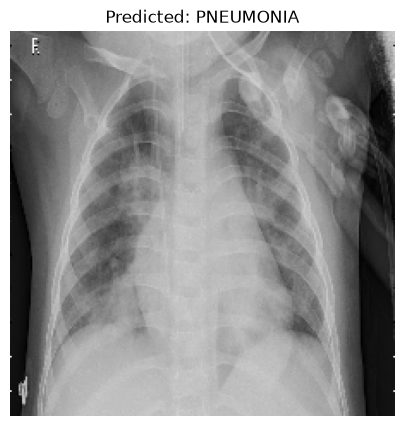

In [25]:
predict_pneumonia(r"C:\Users\nanda\Downloads\person9_bacteria_38.jpeg")

Prediction: NORMAL
Pneumonia probability: 10.66 %


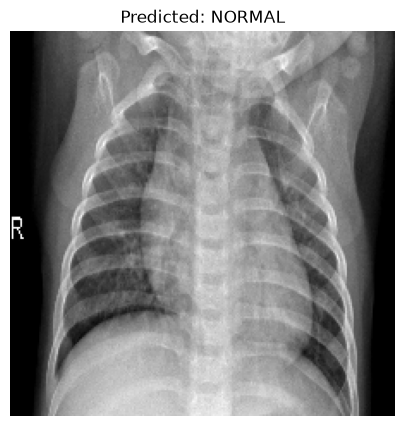

In [26]:
predict_pneumonia(r"C:\Users\nanda\Downloads\NORMAL2-IM-0327-0001.jpeg")

Prediction: PNEUMONIA
Pneumonia probability: 78.87 %


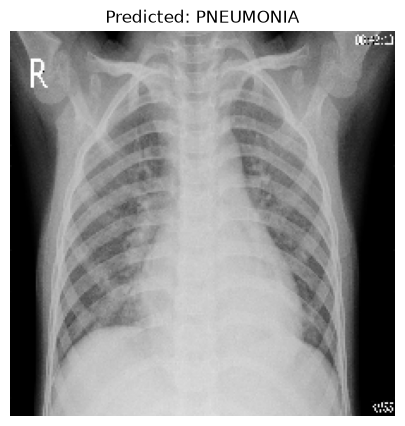

In [27]:
predict_pneumonia(r"C:\Users\nanda\Downloads\person78_virus_140.jpeg")

In [32]:
%pip install ipywidgets

  Using cached colorama-0.4.6-py2.py3-none-any.whl.metadata (17 kB)
  Using cached psutil-7.2.2-cp37-abi3-win_amd64.whl.metadata (22 kB)
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------- ----------- 1.6/2.2 MB 8.3 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 7.4 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 7.4 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 7.4 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 7.4 MB/s eta 0:00:01
   ------------------------------------- -- 2.1/2.2 MB 7.4 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 1.4 MB/s  0:00:01
Using cached colorama-0.4.6-py2.py3-none-any.whl (25 kB)
Using cached psutil-7.2.2-cp37-abi3-win_amd64.whl (137 kB)

   ---------------------------------------- 0/5 [widgetsnbextension]
   -------- ------------------------------- 1/5 [psutil]
   -------- ----------

In [37]:
%pip install --upgrade ipywidgets jupyterlab_widgets

Note: you may need to restart the kernel to use updated packages.


In [1]:
import ipywidgets as widgets
from IPython.display import display

test_button = widgets.Button(description="Test Widget")

display(test_button)

Button(description='Test Widget', style=ButtonStyle())

In [2]:
upload = widgets.FileUpload(
    accept='.jpg,.jpeg,.png',
    multiple=False,
    description='Upload X-ray'
)

display(upload)

FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload X-ray')

In [5]:
import tkinter as tk
from tkinter import filedialog
def upload_and_predict():

    root = tk.Tk()
    root.withdraw()
    root.attributes('-topmost', True)

    image_path = filedialog.askopenfilename(
        title="Select Chest X-ray Image",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png")
        ]
    )

    root.destroy()

    if not image_path:
        print("No image selected.")
        return

    predict_pneumonia(image_path)

In [22]:
from tensorflow.keras.models import load_model

model2 = load_model(
    "../models/model2_final.keras"
)

print("Model 2 loaded successfully!")

Model 2 loaded successfully!


In [23]:
import tkinter as tk
from tkinter import filedialog
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.utils import load_img, img_to_array

def upload_and_predict():

    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    image_path = filedialog.askopenfilename(
        title="Select Chest X-ray",
        filetypes=[("Images", "*.jpg *.jpeg *.png")]
    )

    root.destroy()

    if not image_path:
        print("No image selected.")
        return

    # Load image
    img = load_img(image_path, target_size=(224, 224))

    # Convert image into array
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Predict using trained Model 2
    probability = model2.predict(img_array, verbose=0)[0][0]

    threshold = 0.3

    prediction = (
        "PNEUMONIA" if probability >= threshold
        else "NORMAL"
    )

    print("Selected image:", os.path.basename(image_path))
    print("Prediction:", prediction)
    print("Pneumonia probability:", round(float(probability) * 100, 2), "%")

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title("Prediction: " + prediction)
    plt.axis("off")
    plt.show()

Selected image: person78_virus_140.jpeg
Prediction: PNEUMONIA
Pneumonia probability: 78.87 %


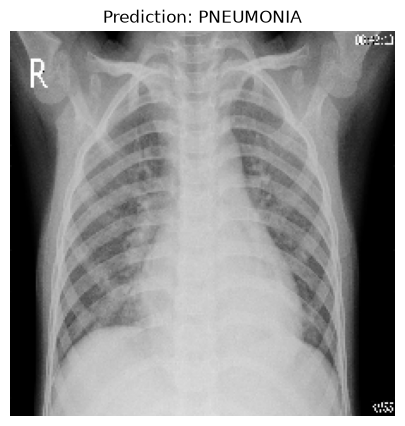

In [15]:
upload_and_predict()

Selected image: person76_virus_138.jpeg
Prediction: PNEUMONIA
Pneumonia probability: 98.28 %


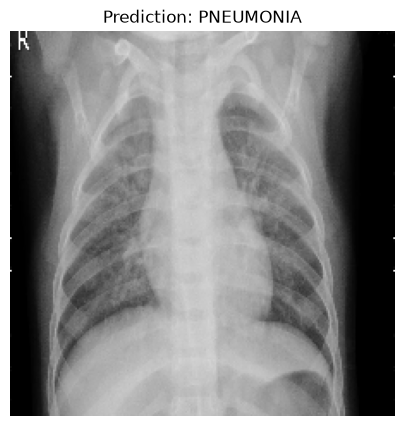

In [24]:
upload_and_predict()

Selected image: NORMAL2-IM-0323-0001.jpeg
Prediction: NORMAL
Pneumonia probability: 6.88 %


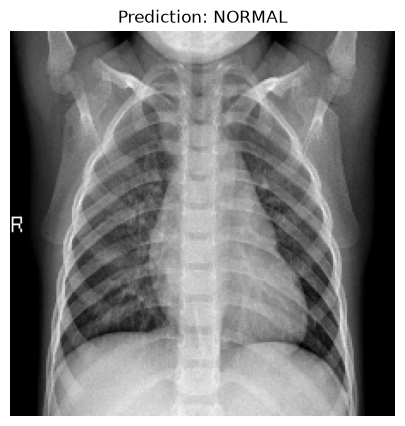

In [25]:
upload_and_predict()

Selected image: NORMAL2-IM-0335-0001.jpeg
Prediction: NORMAL
Pneumonia probability: 6.89 %


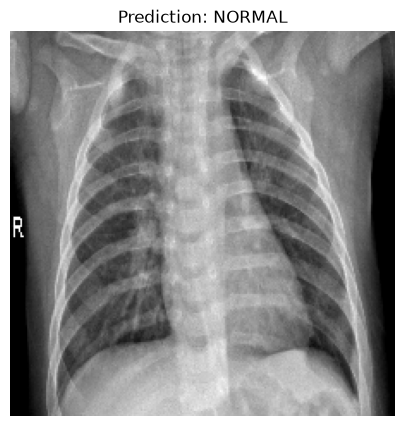

In [26]:
upload_and_predict()

In [19]:
%pip install streamlit

  Using cached streamlit-1.66.1-py3-none-any.whl.metadata (10 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached pyarrow-26.0.1-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached python_multipart-0.0.33-py3-none-any.whl.metadata (6.3 kB)
  Using cached websockets-17.4-cp314-cp314-win_amd64.whl.metadata (6.5 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
Using cached streamlit-1.66.1-py3-none-any.whl (10.4 MB)
Using cached altair-6.3.0-py3-none-any.whl (797 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached itsdangerous-2.2.0-py3-none-any.whl (16 kB)
Using cached pyarrow-26.0.1-cp31

In [20]:
import streamlit as st
print(st.__version__)

1.66.1


In [21]:
import streamlit as st

# Page configuration
st.set_page_config(
    page_title="Pneumonia Detection",
    page_icon="🫁",
    layout="centered"
)

# Application title
st.title("🫁 Pneumonia Detection System")

st.write(
    "Upload a chest X-ray image to get a model prediction."
)

st.info("This is an educational AI project, not a medical diagnostic tool.")

2026-11-05 19:20:21.778 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 19:20:21.780 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 19:20:22.090 
  command:

    streamlit run C:\Users\nanda\.conda\envs\notebook-env\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-05 19:20:22.092 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 19:20:22.094 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 19:20:22.097 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-05 19:20:22.098 Thread 'MainThread': missing ScriptRunContext! This warning can be ig

DeltaGenerator()